# Multi-objective optimization of pharmaceutical tablet production

This notebook analyses historical production records from a tablet-manufacturing process. It answers two questions:

1. Which process measurements carry predictive information about friability on production lots the model has not seen?
2. Which observed operating profiles give the best trade-off between low friability and low compression force?

The analysis combines lot-grouped model validation, an exact Pareto benchmark computed by exhaustive enumeration, and an NSGA-II genetic algorithm whose output is checked against that benchmark.

**Headline result:** the lowest observed friability, 0.25%, was recorded at a compression force of 24.55 kN (record 946, lot 1). This is a candidate for a controlled confirmation batch, not a validated machine setpoint.

## 1. Problem and objectives

Friability (the fraction of tablet mass lost in an abrasion test) varied markedly between production lots. Lower friability is desirable, but reaching it by raising compression force increases punch fatigue and the risk of tooling fracture. The task is therefore treated as a two-objective problem over the observed production records:

| Objective | Quantity | Unit | Direction |
|---|---|---|---|
| $f_1$ | Friability | % | minimize |
| $f_2$ | Compression force | kN | minimize |

The notebook proceeds in five steps:

1. **Data and quality audit:** load the records, check the schema and identify properties that constrain the analysis.
2. **Leakage-aware model validation:** estimate how much predictive signal the process measurements carry, using cross-validation grouped by production lot.
3. **Exact Pareto benchmark:** enumerate all records and keep the non-dominated ones. This is the ground truth.
4. **NSGA-II search:** run a genetic algorithm over the same records and measure how much of the exact front it recovers.
5. **Recommendation:** select a historical profile and check how sensitive the choice is to aggregating records by lot.

All candidates are observed records, and all results describe associations in historical data, not causal effects.

**Requirements:** Python 3.10 or later with `deap`, `matplotlib`, `numpy`, `pandas` and `scikit-learn` (`pip install deap matplotlib numpy pandas scikit-learn`).

In [1]:
import platform
import random
from collections.abc import Iterable, Sequence
from dataclasses import dataclass
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from deap import algorithms, base, creator, tools
from IPython.display import display
from sklearn.base import clone
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold, KFold

print(f"Python {platform.python_version()}")
for package in ["deap", "matplotlib", "numpy", "pandas", "scikit-learn"]:
    print(f"{package:<13}{version(package)}")

Python 3.13.18
deap         1.4.4
matplotlib   3.11.2
numpy        2.5.3
pandas       3.0.5
scikit-learn 1.9.1


In [2]:
REPO_ROOT = Path.cwd()
DATA_PATH = REPO_ROOT / "data" / "private" / "production_batches.csv"

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

NAVY = "#17324D"
TEAL = "#0F766E"
GOLD = "#D97706"
CORAL = "#C2410C"
SLATE = "#64748B"

plt.rcParams.update({
    "figure.dpi": 130,
    "axes.titleweight": "bold",
    "axes.grid": True,
    "grid.alpha": 0.18,
    "legend.frameon": False,
})

## 2. Data and quality audit

### Data access

The production dataset is not distributed with this repository. To reproduce the notebook, place it as a CSV file at `data/private/production_batches.csv`, relative to the directory the notebook is run from. The loader expects the following columns:

| Raw column | Name in this notebook | Unit | Description |
|---|---|---|---|
| first column (unnamed) | `row_id` | – | Record identifier |
| `indice_lote` | `lot_id` | – | Production lot |
| `PreC_VM` | `precompression_kn` | kN | Precompression force |
| `CP_VM` | `compression_kn` | kN | Main compression force |
| `Peso_VM` | `mean_weight_mg` | mg | Mean tablet weight |
| `Peso_min` | `min_weight_mg` | mg | Minimum tablet weight |
| `Peso_max` | `max_weight_mg` | mg | Maximum tablet weight |
| `Diametro_VM` (first occurrence) | `thickness_mm` | mm | Tablet thickness |
| `Dureza_VM` | `hardness_kp` | kp | Tablet hardness |
| `Diametro_VM` (second occurrence) | `diameter_mm` | mm | Tablet diameter |
| `friab` | `friability_fraction` | fraction (0–1) | Lot friability |

The raw file contains two columns named `Diametro_VM`; pandas reads the second one as `Diametro_VM.1`. The first holds values of 5.5–5.8 mm, consistent with tablet thickness, and the second values of about 21 mm, consistent with diameter, which is how they are mapped here.

In [3]:
COLUMN_MAP = {
    "Unnamed: 0": "row_id",
    "indice_lote": "lot_id",
    "PreC_VM": "precompression_kn",
    "CP_VM": "compression_kn",
    "Peso_VM": "mean_weight_mg",
    "Peso_min": "min_weight_mg",
    "Peso_max": "max_weight_mg",
    "Diametro_VM": "thickness_mm",
    "Dureza_VM": "hardness_kp",
    "Diametro_VM.1": "diameter_mm",
    "friab": "friability_fraction",
}

FEATURE_COLUMNS = [
    "precompression_kn",
    "compression_kn",
    "mean_weight_mg",
    "min_weight_mg",
    "max_weight_mg",
    "thickness_mm",
    "hardness_kp",
    "diameter_mm",
]

DISPLAY_NAMES = {
    "precompression_kn": "Precompression",
    "compression_kn": "Compression",
    "mean_weight_mg": "Mean weight",
    "min_weight_mg": "Minimum weight",
    "max_weight_mg": "Maximum weight",
    "thickness_mm": "Thickness",
    "hardness_kp": "Hardness",
    "diameter_mm": "Diameter",
}


def load_production_data(path: str | Path) -> pd.DataFrame:
    data_path = Path(path)
    if not data_path.exists():
        raise FileNotFoundError(
            f"Dataset not found at {data_path}. The production data is not distributed "
            "with this repository. Provide a CSV file at this path containing the raw "
            f"columns {list(COLUMN_MAP)}, with friability ('friab') expressed as a "
            "fraction between 0 and 1."
        )

    raw_data = pd.read_csv(data_path)
    missing_columns = sorted(set(COLUMN_MAP) - set(raw_data.columns))
    if missing_columns:
        raise ValueError(f"Dataset is missing required columns: {missing_columns}")

    data = raw_data.rename(columns=COLUMN_MAP)[list(COLUMN_MAP.values())].copy()
    numeric_columns = ["row_id", "lot_id", *FEATURE_COLUMNS, "friability_fraction"]
    data[numeric_columns] = data[numeric_columns].apply(pd.to_numeric, errors="raise")

    if data[numeric_columns].isna().any().any():
        missing = data[numeric_columns].isna().sum()
        raise ValueError(f"Missing values detected: {missing[missing.gt(0)].to_dict()}")
    if not np.isfinite(data[numeric_columns].to_numpy(dtype=float)).all():
        raise ValueError("Infinite values detected in numeric columns.")
    if not data["friability_fraction"].between(0, 1).all():
        raise ValueError("Friability must be expressed as a fraction between 0 and 1.")
    if data["compression_kn"].le(0).any():
        raise ValueError("Compression force must be positive.")

    data["row_id"] = data["row_id"].astype(int)
    data["lot_id"] = data["lot_id"].astype(int)
    data["friability_pct"] = data["friability_fraction"] * 100
    return data.sort_values("row_id").reset_index(drop=True)


def summarize_data_quality(data: pd.DataFrame) -> dict[str, int | float | bool]:
    compression = data["compression_kn"]
    first_quartile = float(compression.quantile(0.25))
    third_quartile = float(compression.quantile(0.75))
    lower_fence = first_quartile - 1.5 * (third_quartile - first_quartile)

    return {
        "rows": int(len(data)),
        "lots": int(data["lot_id"].nunique()),
        "missing_values": int(data.isna().sum().sum()),
        "duplicate_rows": int(data.duplicated().sum()),
        "repeated_rows_without_id": int(data.drop(columns="row_id").duplicated().sum()),
        "friability_constant_within_lot": bool(
            data.groupby("lot_id")["friability_pct"].nunique().eq(1).all()
        ),
        "compression_lower_fence_kn": round(lower_fence, 3),
        "compression_low_outliers": int(compression.lt(lower_fence).sum()),
    }

In [4]:
data = load_production_data(DATA_PATH)
quality = summarize_data_quality(data)

quality_table = pd.DataFrame(
    {
        "Metric": [
            "Production records",
            "Production lots",
            "Missing values",
            "Duplicate rows (all columns, including row_id)",
            "Repeated measurement rows (row_id excluded)",
            "Friability constant within each lot",
            "Compression IQR lower fence (kN)",
            "Low compression outliers",
        ],
        "Value": [
            quality["rows"],
            quality["lots"],
            quality["missing_values"],
            quality["duplicate_rows"],
            quality["repeated_rows_without_id"],
            quality["friability_constant_within_lot"],
            quality["compression_lower_fence_kn"],
            quality["compression_low_outliers"],
        ],
    }
)
display(quality_table)

record_columns = ["row_id", "lot_id", "friability_pct", "compression_kn"]
low_outliers = data.loc[
    data["compression_kn"].lt(quality["compression_lower_fence_kn"]), record_columns
].copy()
low_outliers["lot_median_compression_kn"] = low_outliers["lot_id"].map(
    data.groupby("lot_id")["compression_kn"].median()
)
print("Compression readings below the IQR lower fence:")
display(low_outliers.round(3))

repeated = data[data.drop(columns="row_id").duplicated(keep=False)]
print("Records whose measurements repeat another record exactly:")
display(repeated[[*record_columns, "hardness_kp", "mean_weight_mg"]])

,Metric,Value
0,Production records,1098
1,Production lots,60
2,Missing values,0
3,"Duplicate rows (all columns, including row_id)",0
4,Repeated measurement rows (row_id excluded),2
5,Friability constant within each lot,True
6,Compression IQR lower fence (kN),8.164
7,Low compression outliers,2


Compression readings below the IQR lower fence:


,row_id,lot_id,friability_pct,compression_kn,lot_median_compression_kn
221,221,19,0.42,1.43,21.57
230,230,20,0.37,0.62,29.91


Records whose measurements repeat another record exactly:


,row_id,lot_id,friability_pct,compression_kn,hardness_kp,mean_weight_mg
733,733,43,0.51,24.84,6.7,1008.9
734,734,43,0.51,26.14,6.2,1006.4
735,735,43,0.51,24.84,6.7,1008.9
736,736,43,0.51,26.14,6.2,1006.4


### Audit findings

- **Friability is a lot-level measurement.** It is constant within every lot and repeated on each process record of that lot. Records from the same lot are therefore not independent, and any validation split that places one lot in both training and test data leaks the target. All model metrics below use cross-validation grouped by lot.
- **Two compression readings are implausibly low.** Both lie far below the IQR lower fence and far below the median of their own lot. They are kept so that the analysis stays faithful to the recorded data, but they are flagged: one of them (0.62 kN) later appears on the Pareto front and must not be read as an operating setpoint without verification.
- **Two records repeat earlier records.** The standard duplicate check finds none because the record identifier differs, but two records in lot 43 repeat the measurements of the two preceding records exactly, which suggests a transcription repeat. They are retained; they are far from the Pareto front and do not affect it.

In [5]:
summary_columns = [*FEATURE_COLUMNS, "friability_pct"]
summary = data[summary_columns].describe().loc[["min", "mean", "50%", "max"]].T
summary.index = [DISPLAY_NAMES.get(name, "Friability") for name in summary.index]
display(summary.round(3))

,min,mean,50%,max
Precompression,0.09,7.101,6.11,21.92
Compression,0.62,34.764,31.26,77.60
Mean weight,982.00,1002.068,1002.10,1027.40
Minimum weight,962.00,986.082,985.80,1017.00
Maximum weight,992.40,1016.132,1015.90,1046.40
Thickness,5.53,5.642,5.64,5.76
Hardness,4.40,8.157,7.30,14.20
Diameter,20.97,21.086,21.10,21.14
Friability,0.25,0.441,0.39,0.75


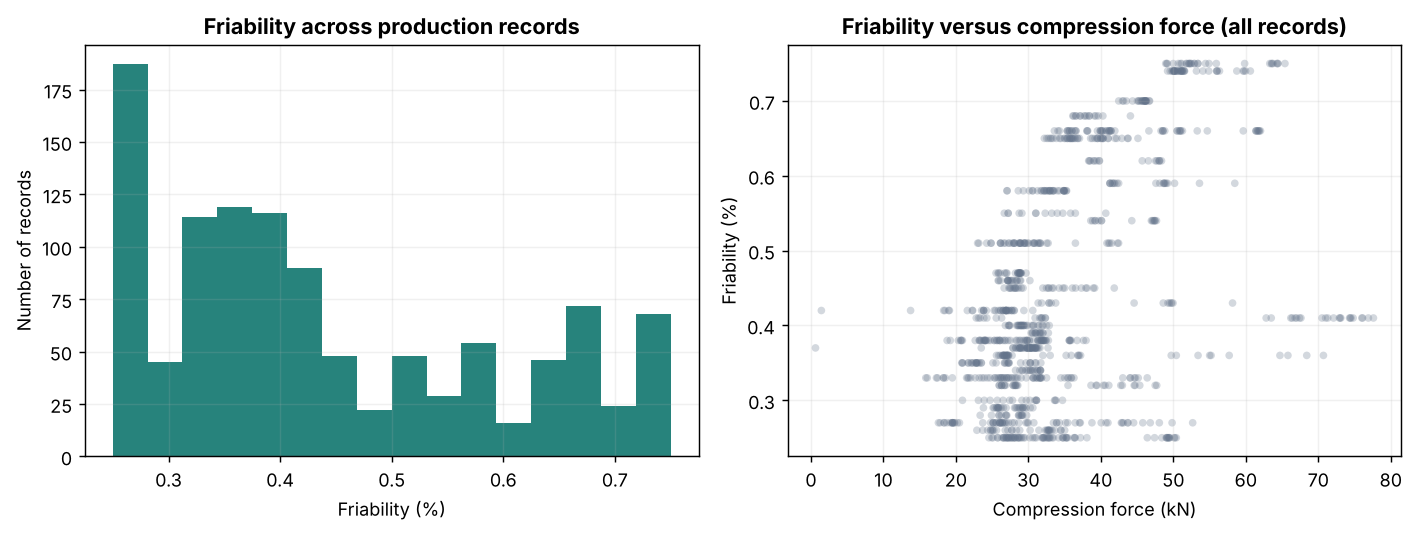

In [6]:
figure, axes = plt.subplots(1, 2, figsize=(11, 4.2))

axes[0].hist(data["friability_pct"], bins=16, color=TEAL, alpha=0.9)
axes[0].set(
    title="Friability across production records",
    xlabel="Friability (%)",
    ylabel="Number of records",
)

axes[1].scatter(
    data["compression_kn"],
    data["friability_pct"],
    s=18,
    alpha=0.28,
    color=SLATE,
    edgecolors="none",
)
axes[1].set(
    title="Friability versus compression force (all records)",
    xlabel="Compression force (kN)",
    ylabel="Friability (%)",
)

figure.tight_layout()
plt.show()

### How to read the objectives

Both objectives are minimized, so in the right-hand plot (and in every friability–compression plot below) better solutions lie toward the **lower-left**. No single record is best on both axes, which is why the problem has a set of trade-off solutions rather than one optimum.

A record $a$ **dominates** a record $b$ if $a$ is no worse than $b$ in both objectives and strictly better in at least one:

$$
a \succ b \iff f_1(a) \le f_1(b),\; f_2(a) \le f_2(b) \;\text{ and }\; \big(f_1(a) < f_1(b) \text{ or } f_2(a) < f_2(b)\big).
$$

The **Pareto front** is the set of records that no other record dominates. Moving along the front, friability can only be reduced by accepting a higher compression force.

## 3. Leakage-aware model validation

An Extra Trees regressor (500 trees, `min_samples_leaf=3`) predicts friability from the eight process measurements. It serves only to quantify and rank predictive signal; the optimization below does not use it.

- **Primary design:** five-fold `GroupKFold` with production lot as the group, so every test fold contains only lots the model has not seen.
- **Diagnostic only:** five-fold random-row `KFold`. Because friability repeats within a lot, this design lets the model see the test lots during training and shows how much a leaky split would overstate performance.
- **Predictive importance:** permutation importance (R² scoring, 10 repeats) is computed on the held-out lots of each grouped fold and averaged over the five folds.

In [7]:
@dataclass(frozen=True)
class ValidationResult:
    grouped_metrics: pd.DataFrame
    random_row_metrics: pd.DataFrame
    feature_importance: pd.DataFrame

    @property
    def summary(self) -> dict[str, float]:
        return {
            "grouped_r2_mean": float(self.grouped_metrics["r2"].mean()),
            "grouped_r2_std": float(self.grouped_metrics["r2"].std(ddof=0)),
            "grouped_mae_mean": float(self.grouped_metrics["mae"].mean()),
            "random_row_r2_mean": float(self.random_row_metrics["r2"].mean()),
            "random_row_r2_std": float(self.random_row_metrics["r2"].std(ddof=0)),
            "random_row_mae_mean": float(self.random_row_metrics["mae"].mean()),
        }


def _new_estimator(random_state: int) -> ExtraTreesRegressor:
    return ExtraTreesRegressor(
        n_estimators=500,
        min_samples_leaf=3,
        random_state=random_state,
        n_jobs=1,
    )


def _metric_row(fold: int, truth: pd.Series, prediction: np.ndarray) -> dict[str, float]:
    return {
        "fold": fold,
        "r2": float(r2_score(truth, prediction)),
        "mae": float(mean_absolute_error(truth, prediction)),
        "rmse": float(np.sqrt(mean_squared_error(truth, prediction))),
    }


def evaluate_model_validation(
    data: pd.DataFrame,
    random_state: int = 42,
) -> ValidationResult:
    features = data[FEATURE_COLUMNS]
    target = data["friability_pct"]
    groups = data["lot_id"]
    base_estimator = _new_estimator(random_state)

    grouped_rows: list[dict[str, float]] = []
    permutation_rows: list[pd.Series] = []
    grouped_splitter = GroupKFold(n_splits=5)
    for fold, (train_index, test_index) in enumerate(
        grouped_splitter.split(features, target, groups), start=1
    ):
        estimator = clone(base_estimator)
        estimator.fit(features.iloc[train_index], target.iloc[train_index])
        prediction = estimator.predict(features.iloc[test_index])
        grouped_rows.append(_metric_row(fold, target.iloc[test_index], prediction))

        importance = permutation_importance(
            estimator,
            features.iloc[test_index],
            target.iloc[test_index],
            scoring="r2",
            n_repeats=10,
            random_state=random_state + fold,
            n_jobs=1,
        )
        permutation_rows.append(
            pd.Series(importance.importances_mean, index=FEATURE_COLUMNS, name=fold)
        )

    random_rows: list[dict[str, float]] = []
    random_splitter = KFold(n_splits=5, shuffle=True, random_state=random_state)
    for fold, (train_index, test_index) in enumerate(
        random_splitter.split(features, target), start=1
    ):
        estimator = clone(base_estimator)
        estimator.fit(features.iloc[train_index], target.iloc[train_index])
        prediction = estimator.predict(features.iloc[test_index])
        random_rows.append(_metric_row(fold, target.iloc[test_index], prediction))

    importance_frame = pd.DataFrame(permutation_rows)
    feature_importance = pd.DataFrame(
        {
            "feature": FEATURE_COLUMNS,
            "importance_mean": importance_frame.mean(axis=0).to_numpy(),
            "importance_std": importance_frame.std(axis=0, ddof=0).to_numpy(),
        }
    ).sort_values("importance_mean", ascending=False, ignore_index=True)

    return ValidationResult(
        grouped_metrics=pd.DataFrame(grouped_rows),
        random_row_metrics=pd.DataFrame(random_rows),
        feature_importance=feature_importance,
    )

In [8]:
validation = evaluate_model_validation(data, random_state=SEED)

validation_summary = pd.DataFrame(
    {
        "Validation design": ["Grouped by lot", "Random rows"],
        "Mean R²": [
            validation.grouped_metrics["r2"].mean(),
            validation.random_row_metrics["r2"].mean(),
        ],
        "R² standard deviation": [
            validation.grouped_metrics["r2"].std(ddof=0),
            validation.random_row_metrics["r2"].std(ddof=0),
        ],
        "Mean MAE (percentage points)": [
            validation.grouped_metrics["mae"].mean(),
            validation.random_row_metrics["mae"].mean(),
        ],
    }
)
display(validation_summary.round(4))

,Validation design,Mean R²,R² standard deviation,Mean MAE (percentage points)
0,Grouped by lot,0.4431,0.1038,0.0869
1,Random rows,0.8461,0.0148,0.0420


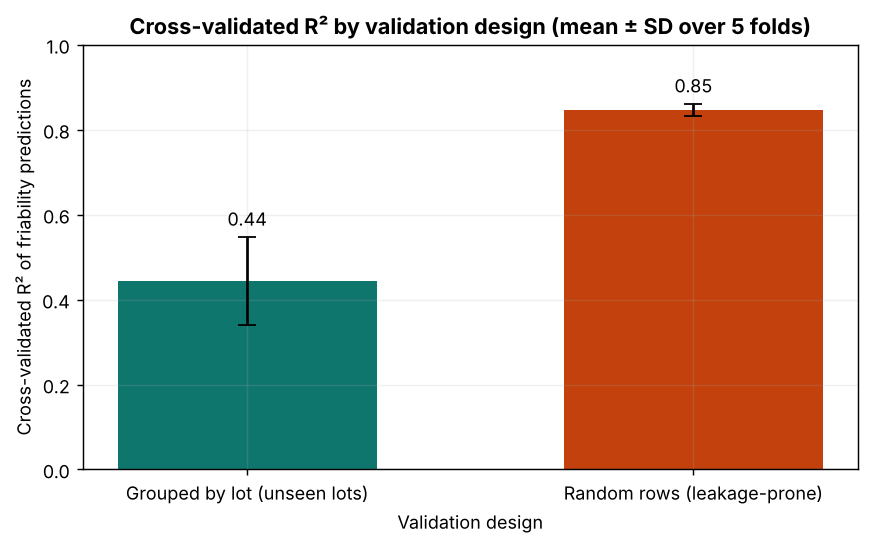

In [9]:
figure, axis = plt.subplots(figsize=(6.8, 4.3))
means = validation_summary["Mean R²"].to_numpy()
errors = validation_summary["R² standard deviation"].to_numpy()
bars = axis.bar(
    ["Grouped by lot (unseen lots)", "Random rows (leakage-prone)"],
    means,
    yerr=errors,
    color=[TEAL, CORAL],
    capsize=5,
    width=0.58,
)
axis.bar_label(bars, labels=[f"{value:.2f}" for value in means], padding=4)
axis.set(
    title="Cross-validated R² by validation design (mean ± SD over 5 folds)",
    xlabel="Validation design",
    ylabel="Cross-validated R² of friability predictions",
    ylim=(0, 1),
)
figure.tight_layout()
plt.show()

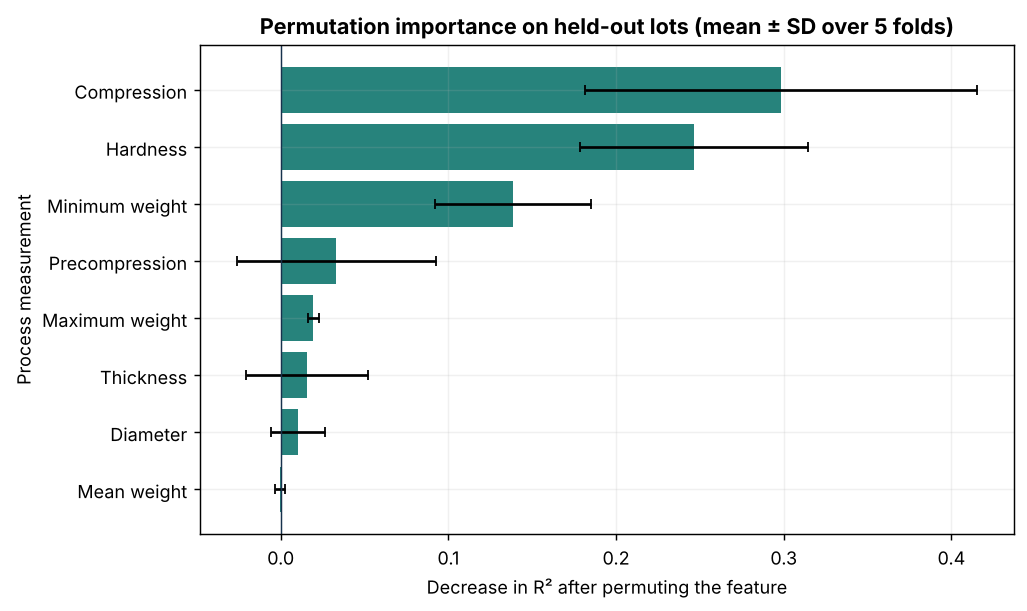

,label,importance_mean,importance_std
0,Compression,0.2983,0.1170
1,Hardness,0.2464,0.0678
2,Minimum weight,0.1387,0.0466
3,Precompression,0.0332,0.0594
4,Maximum weight,0.0195,0.0033


In [10]:
importance = validation.feature_importance.copy()
importance["label"] = importance["feature"].map(DISPLAY_NAMES)
plot_data = importance.sort_values("importance_mean")

figure, axis = plt.subplots(figsize=(8, 4.8))
axis.barh(
    plot_data["label"],
    plot_data["importance_mean"],
    xerr=plot_data["importance_std"],
    color=TEAL,
    alpha=0.9,
    capsize=3,
)
axis.axvline(0, color=NAVY, linewidth=0.8)
axis.set(
    title="Permutation importance on held-out lots (mean ± SD over 5 folds)",
    xlabel="Decrease in R² after permuting the feature",
    ylabel="Process measurement",
)
figure.tight_layout()
plt.show()

display(importance[["label", "importance_mean", "importance_std"]].head(5).round(4))

### Validation findings

- On unseen lots the model explains a moderate share of the variance in friability (grouped R² ≈ 0.44, with substantial variation between folds). The random-row design nearly doubles the apparent R² because it shares lot information between training and test folds; that figure should not be reported as model performance.
- Compression force, hardness and minimum tablet weight carry most of the predictive signal on held-out lots. The remaining measurements contribute little.
- Permutation importance measures predictive association within this dataset. It does not show that changing a measurement would change friability.

## 4. Exact Pareto benchmark

Every record is a candidate with objective pair (friability %, compression kN). Records with identical objective pairs are collapsed (the lowest `row_id` is kept), and each remaining candidate is compared with every other: it stays on the front only if no other candidate dominates it. With about a thousand candidates this pairwise check is immediate, so the exact front is known and serves as ground truth for the genetic algorithm in Section 5.

In [11]:
def non_dominated_mask(values: np.ndarray) -> np.ndarray:
    objective_values = np.asarray(values, dtype=float)
    if objective_values.ndim != 2:
        raise ValueError("Objective values must be a two-dimensional array.")

    mask = np.ones(len(objective_values), dtype=bool)
    for candidate_index, candidate in enumerate(objective_values):
        dominates_candidate = np.all(objective_values <= candidate, axis=1) & np.any(
            objective_values < candidate, axis=1
        )
        dominates_candidate[candidate_index] = False
        if dominates_candidate.any():
            mask[candidate_index] = False
    return mask


def exact_pareto_front(
    data: pd.DataFrame,
    objectives: Sequence[str] = ("friability_pct", "compression_kn"),
) -> pd.DataFrame:
    objective_columns = list(objectives)
    missing_columns = sorted(set(objective_columns) - set(data.columns))
    if missing_columns:
        raise ValueError(f"Missing objective columns: {missing_columns}")

    candidates = (
        data.sort_values([*objective_columns, "row_id"])
        .drop_duplicates(objective_columns, keep="first")
        .reset_index(drop=True)
    )
    mask = non_dominated_mask(candidates[objective_columns].to_numpy(dtype=float))
    return candidates.loc[mask].sort_values(objective_columns).reset_index(drop=True)


def pareto_coverage(
    discovered: pd.DataFrame,
    reference: pd.DataFrame,
    objectives: Sequence[str] = ("friability_pct", "compression_kn"),
    tolerance: float = 1e-9,
) -> float:
    if reference.empty:
        return 1.0
    if discovered.empty:
        return 0.0

    discovered_values = discovered[list(objectives)].to_numpy(dtype=float)
    matched = 0
    for reference_value in reference[list(objectives)].to_numpy(dtype=float):
        close = np.all(
            np.isclose(discovered_values, reference_value, atol=tolerance, rtol=0),
            axis=1,
        )
        matched += int(close.any())
    return matched / len(reference)

In [12]:
exact_front = exact_pareto_front(data)
front_columns = ["row_id", "lot_id", "friability_pct", "compression_kn"]
display(exact_front[front_columns].round(3))

,row_id,lot_id,friability_pct,compression_kn
0,946,1,0.25,24.55
1,628,40,0.26,22.89
2,67,30,0.27,17.58
3,651,6,0.33,15.84
4,230,20,0.37,0.62


The exact front has five points. The last one (0.62 kN, row 230) is one of the two low-compression readings flagged in the audit: it is mathematically non-dominated but physically doubtful.

### 4.1 Why a Pareto method instead of a weighted sum

A common shortcut is to minimize a weighted sum $w\,\tilde f_1 + (1-w)\,\tilde f_2$ of the min–max-normalized objectives. Each weight returns a single record, and sweeping $w$ is expected to trace the trade-off. The cell below sweeps 999 evenly spaced weights in $(0, 1)$ over all records and counts which record each weight selects.

,row_id,lot_id,friability_pct,compression_kn,weights_selecting_point,weight_range
0,946,1,0.25,24.55,306,0.694–0.999
1,628,40,0.26,22.89,0,never selected
2,67,30,0.27,17.58,169,0.525–0.693
3,651,6,0.33,15.84,0,never selected
4,230,20,0.37,0.62,524,0.001–0.524


The weighted sum reaches 3 of 5 Pareto points (rows 67, 230, 946).


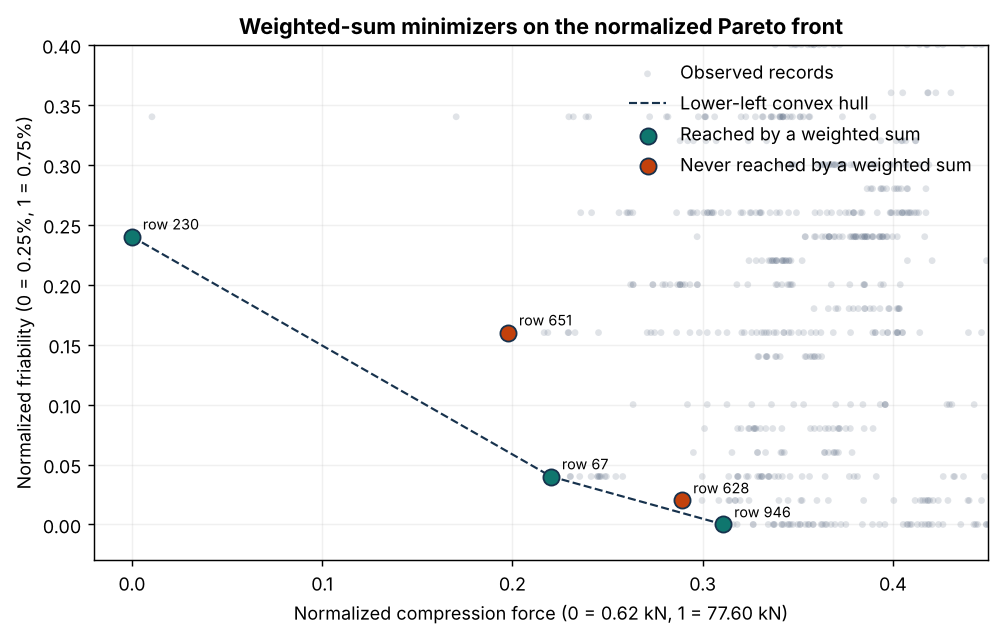

In [13]:
objective_values = data[["friability_pct", "compression_kn"]].to_numpy(dtype=float)
normalized = (objective_values - objective_values.min(axis=0)) / (
    objective_values.max(axis=0) - objective_values.min(axis=0)
)
weights = np.linspace(0.001, 0.999, 999)
selected_rows = np.array(
    [
        int(data["row_id"].iloc[np.argmin(w * normalized[:, 0] + (1 - w) * normalized[:, 1])])
        for w in weights
    ]
)

weighted_sum_table = exact_front[front_columns].copy()
weighted_sum_table["weights_selecting_point"] = [
    int((selected_rows == row_id).sum()) for row_id in exact_front["row_id"]
]
weighted_sum_table["weight_range"] = [
    f"{weights[selected_rows == row_id].min():.3f}–{weights[selected_rows == row_id].max():.3f}"
    if (selected_rows == row_id).any()
    else "never selected"
    for row_id in exact_front["row_id"]
]
reached_rows = sorted(set(selected_rows.tolist()))
assert set(reached_rows) <= set(exact_front["row_id"])
display(weighted_sum_table.round(3))
print(
    f"The weighted sum reaches {len(reached_rows)} of {len(exact_front)} Pareto points "
    f"(rows {', '.join(map(str, reached_rows))})."
)

position_of_row = pd.Series(data.index, index=data["row_id"])
front_normalized = normalized[position_of_row.loc[exact_front["row_id"]].to_numpy()]
reached_mask = exact_front["row_id"].isin(reached_rows).to_numpy()
hull_order = np.argsort(front_normalized[reached_mask][:, 1])

figure, axis = plt.subplots(figsize=(7.8, 5.0))
axis.scatter(
    normalized[:, 1], normalized[:, 0],
    s=14, alpha=0.2, color=SLATE, edgecolors="none", label="Observed records",
)
axis.plot(
    front_normalized[reached_mask][hull_order, 1],
    front_normalized[reached_mask][hull_order, 0],
    linestyle="--", color=NAVY, linewidth=1.2, label="Lower-left convex hull",
)
axis.scatter(
    front_normalized[reached_mask, 1], front_normalized[reached_mask, 0],
    s=80, color=TEAL, edgecolor=NAVY, zorder=4, label="Reached by a weighted sum",
)
axis.scatter(
    front_normalized[~reached_mask, 1], front_normalized[~reached_mask, 0],
    s=80, color=CORAL, edgecolor=NAVY, zorder=4, label="Never reached by a weighted sum",
)
for (row_id, x_value, y_value) in zip(
    exact_front["row_id"], front_normalized[:, 1], front_normalized[:, 0]
):
    axis.annotate(f"row {row_id}", (x_value, y_value), xytext=(6, 4), textcoords="offset points", fontsize=8)
axis.set(
    title="Weighted-sum minimizers on the normalized Pareto front",
    xlabel=(
        f"Normalized compression force (0 = {objective_values[:, 1].min():.2f} kN, "
        f"1 = {objective_values[:, 1].max():.2f} kN)"
    ),
    ylabel=(
        f"Normalized friability (0 = {objective_values[:, 0].min():.2f}%, "
        f"1 = {objective_values[:, 0].max():.2f}%)"
    ),
    xlim=(-0.02, 0.45),
    ylim=(-0.03, 0.4),
)
axis.legend(loc="upper right")
figure.tight_layout()
plt.show()

Across all 999 weights the weighted-sum minimizer lands on only three of the five Pareto points (rows 230, 67 and 946). Rows 651 and 628 lie above the straight line joining their neighbours, in a non-convex part of the front, so no choice of weight selects them; a Pareto-based method such as NSGA-II retains them.

## 5. NSGA-II search and validation against the benchmark

The genetic algorithm searches the same set of historical records. Because the exact answer is known, its output can be scored directly.

| Component | Choice |
|---|---|
| Individual | Index of one historical record (the search is restricted to observed profiles) |
| Fitness | (friability %, compression kN) of that record, both minimized |
| Crossover (p = 0.55) | Blend the two parents' standardized eight-feature profiles with a random weight, then map each child to the nearest record (Euclidean distance) |
| Mutation (p = 0.40) | With probability 0.65 jump to a uniformly random record; otherwise move a random fraction (0.15–0.85) of the way toward a random record and map to the nearest record |
| Selection | NSGA-II non-dominated sorting with crowding distance, (μ + λ) scheme with μ = 120, λ = 240, 60 generations |
| Archive | DEAP `ParetoFront`, keyed on record index |
| Replicates | Three independent runs with seeds 7, 19 and 42; their archives are pooled and filtered to the non-dominated set |

The archive is a `ParetoFront` rather than a fixed-size `HallOfFame`: a hall of fame keeps the *k* best individuals under a lexicographic comparison of fitness values, so it favours the lowest friability and can discard trade-off points.

To show convergence, the archive is a small `ParetoFront` subclass that stores a snapshot of its contents each time `update` is called. `eaMuPlusLambda` calls `update` once for the initial population and once per generation. The snapshot only reads the archive and makes no random draws, so the search itself is unchanged.

In [14]:
if not hasattr(creator, "TabletFitnessMin"):
    creator.create("TabletFitnessMin", base.Fitness, weights=(-1.0, -1.0))
if not hasattr(creator, "TabletCandidate"):
    creator.create("TabletCandidate", list, fitness=creator.TabletFitnessMin)


class RecordingParetoFront(tools.ParetoFront):
    # ParetoFront that calls `on_update(archive)` after every update.

    def __init__(self, similar, on_update):
        super().__init__(similar)
        self._on_update = on_update

    def update(self, population):
        super().update(population)
        self._on_update(self)


@dataclass(frozen=True)
class NSGA2Result:
    front: pd.DataFrame
    unique_candidates_evaluated: int
    total_evaluations: int
    seeds: tuple[int, ...]
    history: pd.DataFrame


def run_nsga2_search(
    data: pd.DataFrame,
    seeds: Iterable[int] = (7, 19, 42),
    population_size: int = 120,
    offspring_size: int = 240,
    generations: int = 60,
) -> NSGA2Result:
    seed_values = tuple(seeds)
    if not seed_values:
        raise ValueError("At least one random seed is required.")

    profiles = data[FEATURE_COLUMNS].to_numpy(dtype=float)
    profile_std = profiles.std(axis=0)
    profile_std[profile_std == 0] = 1.0
    standardized_profiles = (profiles - profiles.mean(axis=0)) / profile_std
    evaluated_indices: set[int] = set()
    archive_indices: set[int] = set()
    total_evaluations = 0
    history_rows: list[dict] = []

    def nearest_candidate(profile: np.ndarray) -> int:
        distances = np.square(standardized_profiles - profile).sum(axis=1)
        return int(np.argmin(distances))

    for seed in seed_values:
        random.seed(seed)
        np.random.seed(seed)
        toolbox = base.Toolbox()
        toolbox.register("candidate_index", random.randrange, len(data))
        toolbox.register(
            "individual", tools.initRepeat, creator.TabletCandidate, toolbox.candidate_index, 1
        )
        toolbox.register("population", tools.initRepeat, list, toolbox.individual)

        def evaluate(individual: list[int]) -> tuple[float, float]:
            nonlocal total_evaluations
            candidate_index = int(individual[0])
            evaluated_indices.add(candidate_index)
            total_evaluations += 1
            row = data.iloc[candidate_index]
            return float(row["friability_pct"]), float(row["compression_kn"])

        def mate(
            first: list[int], second: list[int]
        ) -> tuple[list[int], list[int]]:
            first_profile = standardized_profiles[int(first[0])]
            second_profile = standardized_profiles[int(second[0])]
            blend = random.random()
            first_child = blend * first_profile + (1 - blend) * second_profile
            second_child = (1 - blend) * first_profile + blend * second_profile
            first[0] = nearest_candidate(first_child)
            second[0] = nearest_candidate(second_child)
            return first, second

        def mutate(individual: list[int]) -> tuple[list[int]]:
            if random.random() < 0.65:
                individual[0] = random.randrange(len(data))
                return (individual,)

            current = standardized_profiles[int(individual[0])]
            target = standardized_profiles[random.randrange(len(data))]
            step = random.uniform(0.15, 0.85)
            individual[0] = nearest_candidate(current + step * (target - current))
            return (individual,)

        toolbox.register("evaluate", evaluate)
        toolbox.register("mate", mate)
        toolbox.register("mutate", mutate)
        toolbox.register("select", tools.selNSGA2)

        # Read-only snapshot of the archive after each update (no random draws).
        evaluations_before_seed = total_evaluations
        seed_snapshots: list[dict] = []

        def record_snapshot(archive: tools.ParetoFront) -> None:
            seed_snapshots.append(
                {
                    "seed": seed,
                    "generation": len(seed_snapshots),
                    "evaluations": total_evaluations - evaluations_before_seed,
                    "archive_indices": tuple(sorted(int(ind[0]) for ind in archive)),
                }
            )

        population = toolbox.population(n=population_size)
        pareto_archive = RecordingParetoFront(
            similar=lambda left, right: int(left[0]) == int(right[0]),
            on_update=record_snapshot,
        )
        algorithms.eaMuPlusLambda(
            population,
            toolbox,
            mu=population_size,
            lambda_=offspring_size,
            cxpb=0.55,
            mutpb=0.40,
            ngen=generations,
            halloffame=pareto_archive,
            verbose=False,
        )
        archive_indices.update(int(individual[0]) for individual in pareto_archive)
        history_rows.extend(seed_snapshots)

    archived_candidates = data.iloc[sorted(archive_indices)].copy()
    front = exact_pareto_front(archived_candidates)
    return NSGA2Result(
        front=front,
        unique_candidates_evaluated=len(evaluated_indices),
        total_evaluations=total_evaluations,
        seeds=seed_values,
        history=pd.DataFrame(history_rows),
    )

In [15]:
ga_result = run_nsga2_search(data, seeds=(7, 19, 42))
coverage = pareto_coverage(ga_result.front, exact_front)

ga_summary = pd.DataFrame(
    {
        "Metric": [
            "Exact Pareto points",
            "NSGA-II Pareto points",
            "Pareto coverage",
            "Unique historical candidates evaluated",
            "Total fitness evaluations",
            "Seeds",
        ],
        "Value": [
            len(exact_front),
            len(ga_result.front),
            f"{coverage:.0%}",
            ga_result.unique_candidates_evaluated,
            ga_result.total_evaluations,
            ", ".join(map(str, ga_result.seeds)),
        ],
    }
)
display(ga_summary)

,Metric,Value
0,Exact Pareto points,5
1,NSGA-II Pareto points,5
2,Pareto coverage,100%
3,Unique historical candidates evaluated,1098
4,Total fitness evaluations,41403
5,Seeds,"7, 19, 42"


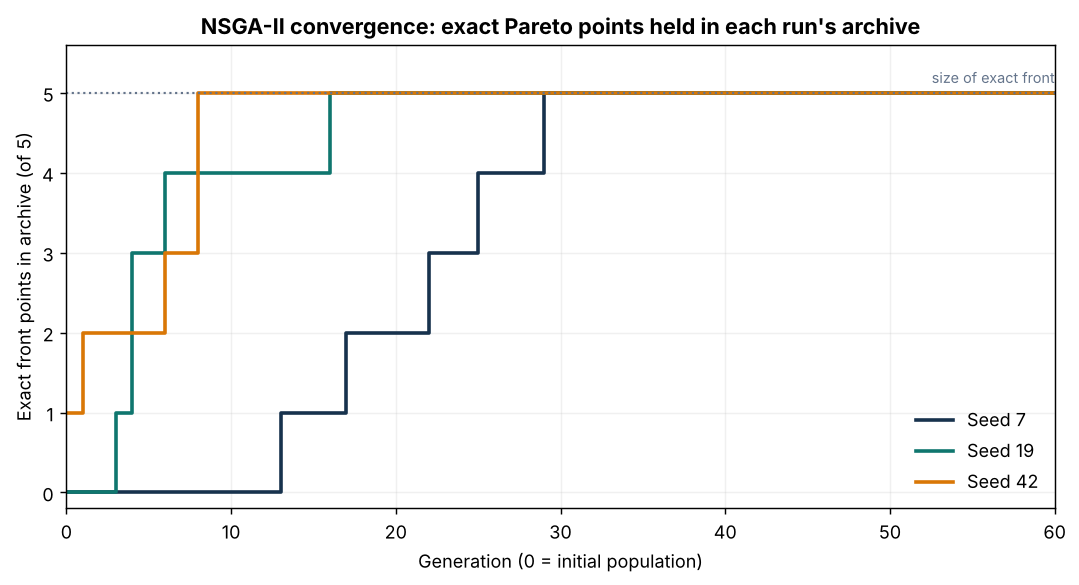

,Seed,First generation with all 5 points,Cumulative evaluations at that generation,Evaluations in the full 60-generation run
0,7,29,6698,13785
1,19,16,3761,13794
2,42,8,1938,13824


In [16]:
history = ga_result.history.copy()
history["front_points_found"] = [
    round(pareto_coverage(data.iloc[list(indices)], exact_front) * len(exact_front))
    for indices in history["archive_indices"]
]
assert history.groupby("seed")["generation"].max().eq(60).all()
assert history.groupby("seed")["evaluations"].max().sum() == ga_result.total_evaluations

figure, axis = plt.subplots(figsize=(8.4, 4.6))
for seed, color in zip(ga_result.seeds, [NAVY, TEAL, GOLD]):
    seed_history = history[history["seed"] == seed]
    axis.step(
        seed_history["generation"], seed_history["front_points_found"],
        where="post", color=color, linewidth=2, label=f"Seed {seed}",
    )
axis.axhline(len(exact_front), color=SLATE, linestyle=":", linewidth=1.2)
axis.text(60, len(exact_front) + 0.08, "size of exact front", ha="right", va="bottom", fontsize=8, color=SLATE)
axis.set(
    title="NSGA-II convergence: exact Pareto points held in each run's archive",
    xlabel="Generation (0 = initial population)",
    ylabel="Exact front points in archive (of 5)",
    xlim=(0, 60),
    ylim=(-0.2, len(exact_front) + 0.6),
)
axis.legend(loc="lower right")
figure.tight_layout()
plt.show()

full = history[history["front_points_found"] == len(exact_front)]
convergence_table = pd.DataFrame(
    {
        "Seed": list(ga_result.seeds),
        "First generation with all 5 points": [
            int(full.loc[full["seed"] == seed, "generation"].min()) for seed in ga_result.seeds
        ],
        "Cumulative evaluations at that generation": [
            int(full.loc[full["seed"] == seed, "evaluations"].min()) for seed in ga_result.seeds
        ],
        "Evaluations in the full 60-generation run": [
            int(history.loc[history["seed"] == seed, "evaluations"].max()) for seed in ga_result.seeds
        ],
    }
)
display(convergence_table)

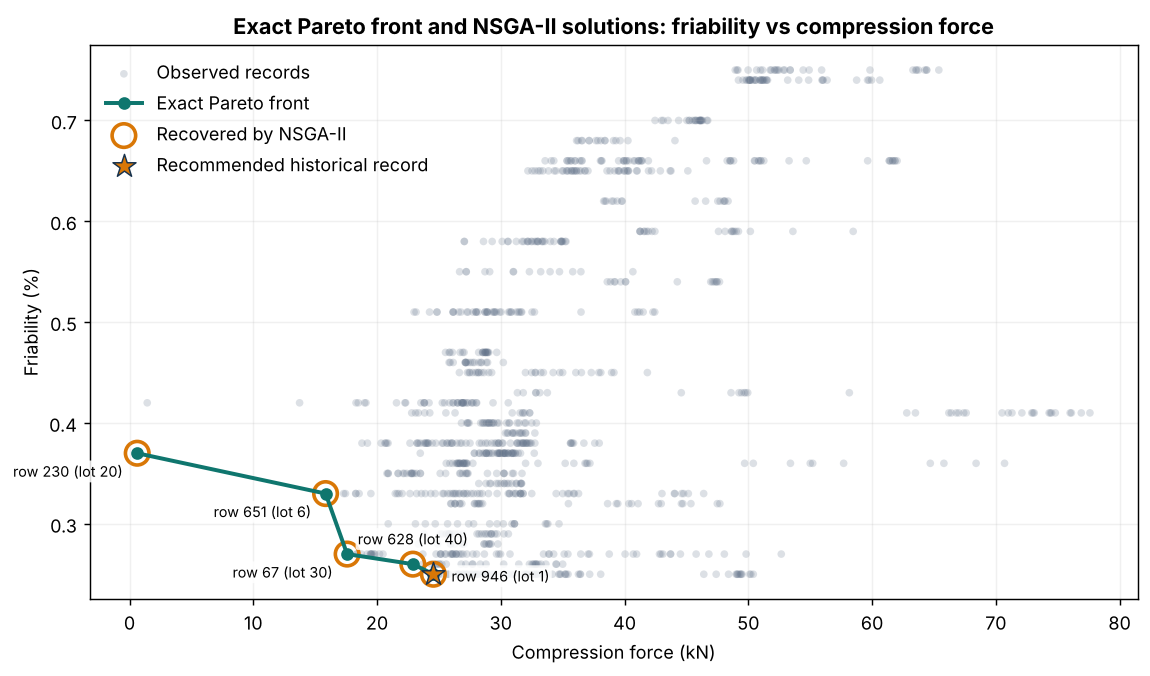

In [17]:
def label_front_points(axis, x_values, y_values, labels) -> None:
    # Place labels so that neighbouring front points do not overlap:
    # the highest-force point is labelled to the right, the next one above,
    # and the remaining points below-left.
    order = np.argsort(np.asarray(x_values))[::-1]
    for rank, index in enumerate(order):
        offset, alignment = [((10, -4), "left"), ((0, 11), "center")][rank] if rank < 2 else ((-8, -13), "right")
        axis.annotate(
            labels[index], (x_values[index], y_values[index]),
            xytext=offset, textcoords="offset points", ha=alignment, fontsize=8,
            bbox=dict(boxstyle="round,pad=0.15", facecolor="white", edgecolor="none", alpha=0.85),
        )


recommendation = exact_front.sort_values(["friability_pct", "compression_kn"]).iloc[0]
ordered_front = exact_front.sort_values("compression_kn")

figure, axis = plt.subplots(figsize=(9, 5.3))
axis.scatter(
    data["compression_kn"], data["friability_pct"],
    s=18, alpha=0.22, color=SLATE, edgecolors="none", label="Observed records"
)
axis.plot(
    ordered_front["compression_kn"], ordered_front["friability_pct"],
    marker="o", linewidth=2.2, color=TEAL, label="Exact Pareto front"
)
axis.scatter(
    ga_result.front["compression_kn"], ga_result.front["friability_pct"],
    s=170, facecolors="none", edgecolors=GOLD, linewidth=2,
    label="Recovered by NSGA-II"
)
axis.scatter(
    [recommendation["compression_kn"]], [recommendation["friability_pct"]],
    marker="*", s=180, color=GOLD, edgecolor=NAVY, linewidth=0.8,
    label="Recommended historical record", zorder=5
)
label_front_points(
    axis,
    exact_front["compression_kn"].to_numpy(),
    exact_front["friability_pct"].to_numpy(),
    [f"row {int(row)} (lot {int(lot)})" for row, lot in zip(exact_front["row_id"], exact_front["lot_id"])],
)
axis.set(
    title="Exact Pareto front and NSGA-II solutions: friability vs compression force",
    xlabel="Compression force (kN)",
    ylabel="Friability (%)",
)
axis.legend(loc="upper left")
figure.tight_layout()
plt.show()

### Search findings

- Pooled over three seeds, NSGA-II recovers all five exact Pareto points, and each run on its own holds the complete front well before generation 60 (see the convergence table).
- The three runs used 41,403 fitness evaluations and between them visited every one of the 1,098 records. Because the exact front is available for this dataset, the output of the genetic algorithm is verified rather than assumed. That check is the basis for applying the same search where no exact answer exists, for example to continuous machine settings evaluated through a surrogate model.

## 6. Recommendation and results summary

Of the five Pareto points, the one with the lowest friability is selected as the candidate profile. The 0.62 kN point is not a candidate because it is a flagged reading. The first version of this analysis used a scalar `HallOfFame(20)` and reported 25.76 kN as the lowest force at 0.25% friability; the comparison below quantifies the refinement obtained with the exact front.

In [18]:
ORIGINAL_GA_FORCE_KN = 25.76  # best force at 0.25% friability reported by the first version

pressure_reduction_original = (
    ORIGINAL_GA_FORCE_KN - recommendation["compression_kn"]
) / ORIGINAL_GA_FORCE_KN * 100
pressure_reduction_median = (
    data["compression_kn"].median() - recommendation["compression_kn"]
) / data["compression_kn"].median() * 100

recommendation_table = pd.DataFrame(
    {
        "Metric": [
            "Historical row",
            "Production lot",
            "Friability",
            "Compression force",
            "Pressure reduction vs. original GA",
            "Pressure reduction vs. dataset median",
        ],
        "Value": [
            int(recommendation["row_id"]),
            int(recommendation["lot_id"]),
            f"{recommendation['friability_pct']:.2f}%",
            f"{recommendation['compression_kn']:.2f} kN",
            f"{pressure_reduction_original:.1f}%",
            f"{pressure_reduction_median:.1f}%",
        ],
    }
)
display(recommendation_table)

,Metric,Value
0,Historical row,946
1,Production lot,1
2,Friability,0.25%
3,Compression force,24.55 kN
4,Pressure reduction vs. original GA,4.7%
5,Pressure reduction vs. dataset median,21.5%


### 6.1 Robustness analysis: lot-level sensitivity check

Friability is measured once per lot, whereas compression force varies from record to record within a lot. The record-level front above therefore pairs a lot's friability with a single compression reading. As a sensitivity check, the front is recomputed with one point per lot: lot friability against the **mean** compression force of that lot's records. A second variant excludes the two flagged low readings before averaging.

,lot_id,friability_pct,mean_compression_kn,min_compression_kn,records,lot_on_record_level_front
0,33,0.25,27.53,25.11,18,False
1,40,0.26,26.14,22.89,16,True
2,30,0.27,22.56,17.58,23,True
3,6,0.33,20.21,15.84,16,True
4,19,0.42,19.32,1.43,13,False


Lots on both the record-level and lot-level fronts: [40, 30, 6]
Mean compression force of lot 1 (contains row 946): 29.52 kN
Lot-level front without the two flagged low readings: lots [33, 40, 30, 6]


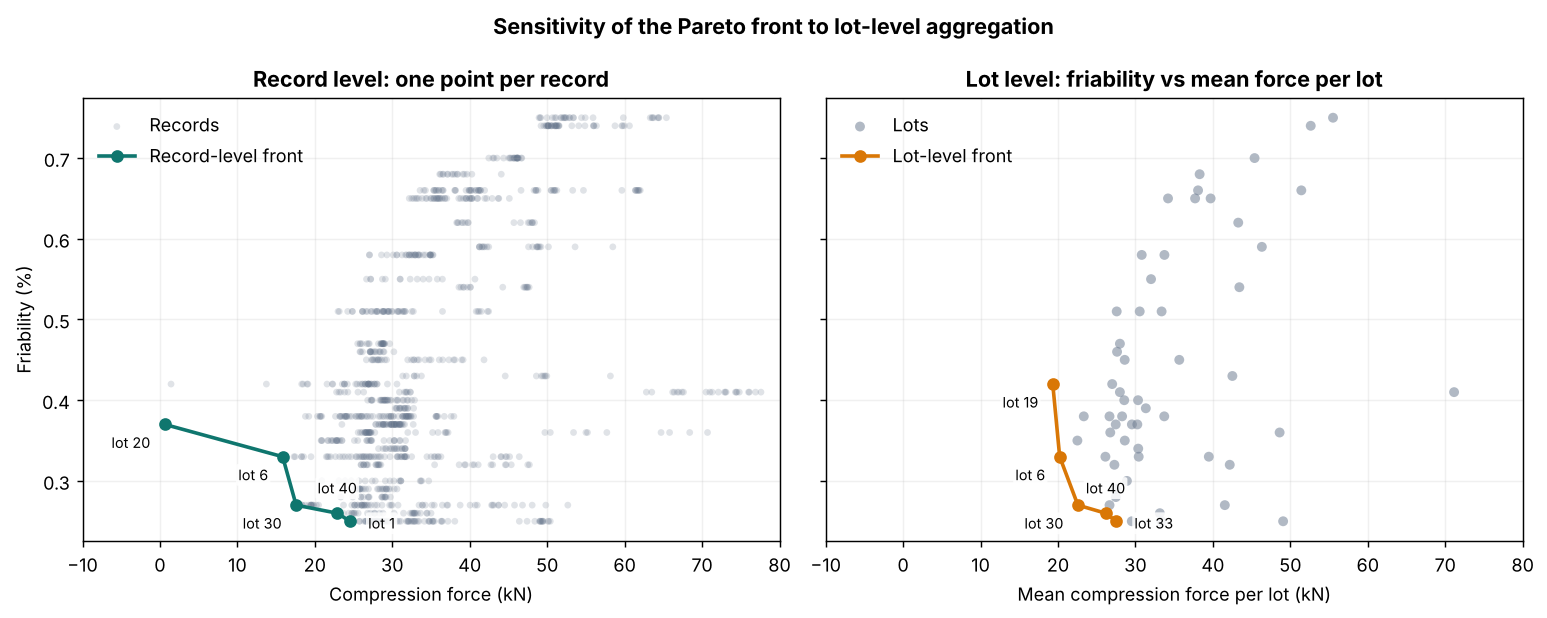

In [19]:
def lot_level_front(records: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    lots = (
        records.groupby("lot_id")
        .agg(
            friability_pct=("friability_pct", "first"),
            mean_compression_kn=("compression_kn", "mean"),
            min_compression_kn=("compression_kn", "min"),
            records=("row_id", "size"),
        )
        .reset_index()
    )
    mask = non_dominated_mask(lots[["friability_pct", "mean_compression_kn"]].to_numpy())
    front = lots.loc[mask].sort_values("friability_pct").reset_index(drop=True)
    return lots, front


lot_summary, lot_front = lot_level_front(data)
lot_front["lot_on_record_level_front"] = lot_front["lot_id"].isin(exact_front["lot_id"])
display(lot_front.round(2))

clean_records = data[data["compression_kn"].ge(quality["compression_lower_fence_kn"])]
_, lot_front_clean = lot_level_front(clean_records)
shared_lots = [lot for lot in lot_front["lot_id"] if lot in set(exact_front["lot_id"])]
recommended_lot_mean = lot_summary.loc[
    lot_summary["lot_id"] == int(recommendation["lot_id"]), "mean_compression_kn"
].iloc[0]
print(f"Lots on both the record-level and lot-level fronts: {shared_lots}")
print(f"Mean compression force of lot {int(recommendation['lot_id'])} (contains row "
      f"{int(recommendation['row_id'])}): {recommended_lot_mean:.2f} kN")
print(f"Lot-level front without the two flagged low readings: lots {lot_front_clean['lot_id'].tolist()}")

figure, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
axes[0].scatter(data["compression_kn"], data["friability_pct"], s=14, alpha=0.2, color=SLATE, edgecolors="none", label="Records")
axes[0].plot(ordered_front["compression_kn"], ordered_front["friability_pct"], marker="o", color=TEAL, linewidth=2, label="Record-level front")
label_front_points(
    axes[0], exact_front["compression_kn"].to_numpy(), exact_front["friability_pct"].to_numpy(),
    [f"lot {int(lot)}" for lot in exact_front["lot_id"]],
)
axes[0].set(title="Record level: one point per record", xlabel="Compression force (kN)", ylabel="Friability (%)")
axes[0].legend(loc="upper left")

ordered_lot_front = lot_front.sort_values("mean_compression_kn")
axes[1].scatter(lot_summary["mean_compression_kn"], lot_summary["friability_pct"], s=30, alpha=0.5, color=SLATE, edgecolors="none", label="Lots")
axes[1].plot(ordered_lot_front["mean_compression_kn"], ordered_lot_front["friability_pct"], marker="o", color=GOLD, linewidth=2, label="Lot-level front")
label_front_points(
    axes[1], lot_front["mean_compression_kn"].to_numpy(), lot_front["friability_pct"].to_numpy(),
    [f"lot {int(lot)}" for lot in lot_front["lot_id"]],
)
axes[1].set(title="Lot level: friability vs mean force per lot", xlabel="Mean compression force per lot (kN)")
axes[1].legend(loc="upper left")
for axis in axes:
    axis.set_xlim(-10, 80)
figure.suptitle("Sensitivity of the Pareto front to lot-level aggregation", fontweight="bold")
figure.tight_layout()
plt.show()

**What is stable.** Lots 40, 30 and 6 are on the front at both levels of aggregation, so the shape of the trade-off between about 0.26% and 0.33% friability does not depend on how records are aggregated.

**What changes.** At lot level, the lowest-friability (0.25%) lot with the lowest mean force is lot 33, at about 27.5 kN; lot 1, which contains record 946, averages about 29.5 kN. The 0.62 kN reading no longer defines a front point, because lot 20 averages about 27.5 kN. Lot 19 enters the lot-level front at 0.42%, but only because its mean includes the second flagged low reading (1.43 kN); without the two flagged readings the lot-level front consists of lots 33, 40, 30 and 6.

**Implication for the confirmation batch.** The 24.55 kN figure is a single reading within a lot whose typical force was higher. A confirmation batch should test whether 0.25% friability is reproduced when the press is run at that force, using lots 1 and 33 as the historical references.

In [20]:
results_summary = pd.DataFrame(
    [
        ("Production records / lots", f"{quality['rows']:,} / {quality['lots']}"),
        ("Grouped-by-lot R² (mean ± SD)", f"{validation.summary['grouped_r2_mean']:.4f} ± {validation.summary['grouped_r2_std']:.4f}"),
        ("Random-row R², diagnostic only (mean ± SD)", f"{validation.summary['random_row_r2_mean']:.4f} ± {validation.summary['random_row_r2_std']:.4f}"),
        ("Top three predictive signals", ", ".join(importance["label"].head(3))),
        ("Exact Pareto points", len(exact_front)),
        ("NSGA-II Pareto coverage (seeds pooled)", f"{coverage:.0%}"),
        ("NSGA-II total fitness evaluations", f"{ga_result.total_evaluations:,}"),
        ("Pareto points reachable by a weighted sum", f"{len(reached_rows)} of {len(exact_front)}"),
        ("Recommended record (row / lot)", f"{int(recommendation['row_id'])} / {int(recommendation['lot_id'])}"),
        ("Friability at the recommended record", f"{recommendation['friability_pct']:.2f}%"),
        ("Compression force at the recommended record", f"{recommendation['compression_kn']:.2f} kN"),
        ("Reduction vs. first-version GA / vs. median force", f"{pressure_reduction_original:.1f}% / {pressure_reduction_median:.1f}%"),
        ("Lot-level front (lot ids)", ", ".join(map(str, lot_front["lot_id"]))),
    ],
    columns=["Result", "Value"],
)
display(results_summary)

,Result,Value
0,Production records / lots,"1,098 / 60"
1,Grouped-by-lot R² (mean ± SD),0.4431 ± 0.1038
2,"Random-row R², diagnostic only (mean ± SD)",0.8461 ± 0.0148
3,Top three predictive signals,"Compression, Hardness, Minimum weight"
4,Exact Pareto points,5
5,NSGA-II Pareto coverage (seeds pooled),100%
6,NSGA-II total fitness evaluations,"41,403"
7,Pareto points reachable by a weighted sum,3 of 5
8,Recommended record (row / lot),946 / 1
9,Friability at the recommended record,0.25%


## 7. Scientific foundation

We gratefully acknowledge **Julieta Villar Alvez**, author of *Factores que afectan a la compresión de comprimidos* (Universidad de Sevilla, 2017). Her experimental work was the principal pharmaceutical reference used to interpret the results of the genetic algorithm, in particular the relationships among compression pressure, hardness, friability, formulation, humidity and compression time.

The institutional record classifies the document as an **experimental Final Degree Project in Pharmacy**. It provides the domain rationale for the quality–pressure trade-off; the numerical recommendation in this notebook comes from the production dataset, the exact Pareto calculation and the NSGA-II validation.

- [Official idUS record](https://idus.us.es/items/de5f0215-310f-4c95-b62e-fef0714b5a69)
- [Full document](https://idus.us.es/server/api/core/bitstreams/ff0722b4-1a38-47be-829d-ffdb4f5796d7/content)

## 8. Limitations and next steps

1. **Observational evidence:** the data were not collected under a designed experiment. Feature importance is predictive, not causal, and the Pareto points describe what was observed together, not what a setting will produce.
2. **Lot-level target:** friability is measured once per lot and repeated across process records. The model has effectively 60 independent target values, and the record-level front pairs a lot's friability with individual force readings (see Section 6.1).
3. **Data quality:** two compression readings (0.62 and 1.43 kN) are implausibly low and one of them defines a Pareto point; two records in lot 43 repeat earlier records. Both issues should be checked against the source records.
4. **Historical candidates only:** the optimizer ranks observed profiles and does not generate new continuous machine setpoints.
5. **Production validation:** the recommended profile requires engineering review and a controlled confirmation batch before any change to the process.
6. **Next step:** collect designed experiments around the candidate region, train a constrained surrogate model on them, and apply the validated NSGA-II search to continuous controllable settings with an uncertainty penalty.